| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_2_Gradient_methods.ipynb) | [⏩](../10_OPTIMIZACION/10_4_Optimizacion_restringida.ipynb) |

# 10.3 Métodos de segundo orden: Newton, Gauss–Newton y BFGS

**Objetivo del cuaderno.** usar la curvatura para construir pasos, entender por qué Newton necesita protección y calibrar un modelo no lineal

**Antes de empezar:** Taylor multivariable, Hessiano, Jacobiano y sistemas lineales. Ejecuta las celdas de arriba hacia abajo. Los datos se generan localmente y la semilla hace repetible el experimento; las conclusiones numéricas corresponden a este conjunto de datos.

**Ruta de estudio:** primero formula el problema y entiende las ecuaciones; después compara las figuras con las predicciones teóricas; finalmente modifica un parámetro y resuelve los ejercicios. En cada gráfico distinguimos lo que demuestra el experimento de lo que requiere una hipótesis matemática.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'font.size': 11})
rng = np.random.default_rng(42)

## 1. De la aproximación lineal a la cuadrática

Newton minimiza el modelo local $m(p)=J(\theta)+g^Tp+\tfrac12p^THp$. Su condición estacionaria es $Hp=-g$, y la iteración es $\theta_{n+1}=\theta_n+p$. Si $H$ es definida positiva, ese paso minimiza el modelo y $g^Tp=-g^TH^{-1}g<0$ para $g\ne0$.

No invertimos explícitamente el Hessiano: resolvemos un sistema. Si $H$ es indefinida, Newton puede dirigirse a un máximo o a una silla. Un Hessiano singular requiere modificar el modelo o el método.

## 2. Convergencia local y coste

Bajo hipótesis de suavidad, Hessiano no singular en el mínimo y un inicio suficientemente cercano, Newton tiene convergencia cuadrática: $\|e_{n+1}\|\le C\|e_n\|^2$. Esa afirmación es local, no dice qué ocurre desde cualquier inicio.

Un Hessiano denso ocupa $O(d^2)$ memoria y un sistema denso cuesta aproximadamente $O(d^3)$. Para millones de parámetros son más útiles productos Hessiano-vector, aproximaciones diagonales o métodos cuasi-Newton limitados en memoria. Contar iteraciones sin contar evaluaciones y factorizaciones puede esconder el verdadero coste.

## 3. Una cuadrática: Newton exacto en un paso

Tomamos $J(\theta)=\tfrac12\theta^TA\theta-b^T\theta$. Como Taylor de orden dos es exacto, un paso de Newton llega a $A^{-1}b$ desde cualquier inicio.

Referencia: [ 0.35714 -0.57143] Newton: [ 0.35714 -0.57143]


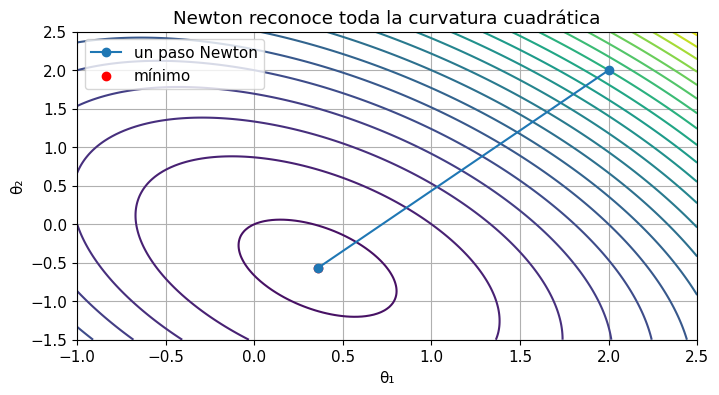

In [2]:
A=np.array([[6.,2.],[2.,3.]])
b=np.array([1.,-1.]);x0=np.array([2.,2.])
x_star=np.linalg.solve(A,b)
newton_step=np.linalg.solve(A,-(A@x0-b));x1=x0+newton_step
print('Referencia:',x_star,'Newton:',x1)
assert np.allclose(x1,x_star)
u,v=np.meshgrid(np.linspace(-1,2.5,160),np.linspace(-1.5,2.5,160))
z=0.5*(6*u*u+4*u*v+3*v*v)-u+v
plt.contour(u,v,z,levels=22)
plt.plot([x0[0],x1[0]],[x0[1],x1[1]],'o-',label='un paso Newton')
plt.scatter(*x_star,c='red',label='mínimo');plt.xlabel('θ₁');plt.ylabel('θ₂')
plt.title('Newton reconoce toda la curvatura cuadrática');plt.legend();plt.show()

**Interpretación.** El paso atraviesa las elipses sin el zigzag típico del gradiente. Es una propiedad de este objetivo exactamente cuadrático con Hessiano definido positivo, no una regla universal para pérdidas de redes neuronales.

## 4. Un fallo explicable de Newton sin protección

Para $J(x)=x^4-x^2$, tenemos $J'(x)=4x^3-2x$ y $J''(x)=12x^2-2$. En el origen el gradiente se anula y la segunda derivada es negativa: es un máximo local. Si iniciamos cerca de cero, Newton puede converger al máximo porque también es un método para resolver $J'(x)=0$.

Una estrategia sencilla modifica la curvatura mediante $H+\lambda I$ y controla el paso con una búsqueda. La regularización debe ser suficiente para conseguir una dirección de descenso.

Sin protección: 0.0 Con protección: 0.7071067811865492


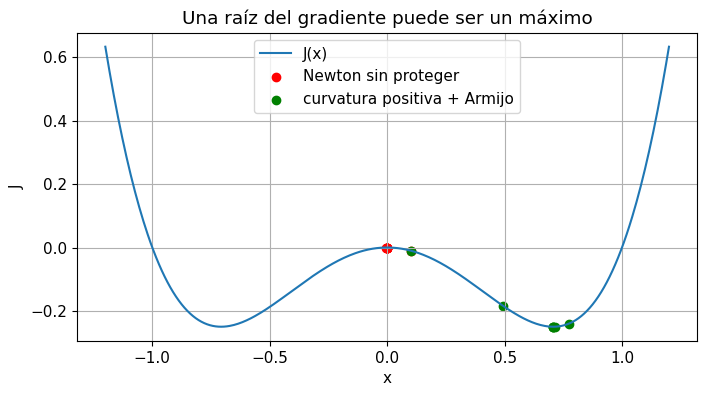

In [3]:
def f1(x):return x**4-x**2
def g1(x):return 4*x**3-2*x
def h1(x):return 12*x*x-2
plain=[0.1];protected=[0.1]
for _ in range(8):
    q=plain[-1];plain.append(q-g1(q)/h1(q))
for _ in range(12):
    q=protected[-1]
    if abs(g1(q))<1e-10:break
    curvature=max(h1(q),0.5)
    step=-g1(q)/curvature;alpha=1.
    while f1(q+alpha*step)>f1(q)+1e-4*alpha*g1(q)*step:alpha*=0.5
    protected.append(q+alpha*step)
x=np.linspace(-1.2,1.2,400);plt.plot(x,f1(x),label='J(x)')
plt.scatter(plain,[f1(q) for q in plain],label='Newton sin proteger',c='r')
plt.scatter(protected,[f1(q) for q in protected],label='curvatura positiva + Armijo',c='g')
plt.xlabel('x');plt.ylabel('J');plt.title('Una raíz del gradiente puede ser un máximo');plt.legend();plt.show()
print('Sin protección:',plain[-1], 'Con protección:',protected[-1])

## 5. Región de confianza y amortiguamiento

La búsqueda de línea conserva una dirección y decide cuánto avanzar. Una región de confianza limita $\|p\|\le\Delta$ y decide una dirección dentro de una zona donde el modelo cuadrático es creíble. Compara reducción real con reducción predicha; una mala concordancia reduce el radio.

El amortiguamiento $(H+\lambda I)p=-g$ suaviza direcciones de poca o negativa curvatura. No es idéntico a añadir permanentemente $\lambda\|\theta\|^2$ al objetivo: aquí $\lambda$ puede ser un recurso del algoritmo que cambia en cada iteración.

## 6. Mínimos cuadrados no lineales y Gauss–Newton

Si $J=\tfrac12\|r(\theta)\|^2$ y $R$ es el Jacobiano del vector de residuos,

$$g=R^Tr,\qquad H=R^TR+\sum_i r_i\nabla^2r_i.$$

Gauss–Newton omite el segundo término y resuelve $R^TRp=-R^Tr$. Es una buena aproximación cuando los residuos son pequeños o su curvatura adicional es modesta. Si $R$ tiene columnas casi dependientes, el sistema queda mal condicionado. Las ecuaciones normales elevan al cuadrado el número de condición: en una implementación robusta se prefiere QR, SVD o un solver de mínimos cuadrados.

Levenberg–Marquardt añade $\lambda I$ a $R^TR$. Para $\lambda$ grande el paso se parece a un gradiente escalado; para $\lambda$ pequeño se aproxima a Gauss–Newton.

## 7. Calibración de amplitud y decaimiento

El modelo $u(t;a,k)=a e^{-kt}$ tiene dos parámetros. Los residuos son $r_i=a e^{-kt_i}-y_i$; las columnas de $R$ son $e^{-kt_i}$ y $-at_i e^{-kt_i}$. Usamos datos reservados que no entran en el ajuste.

Parámetros reales: [1.4  0.65] Estimados: [1.39637 0.64336]
MSE reservado: 0.0002842721918255616


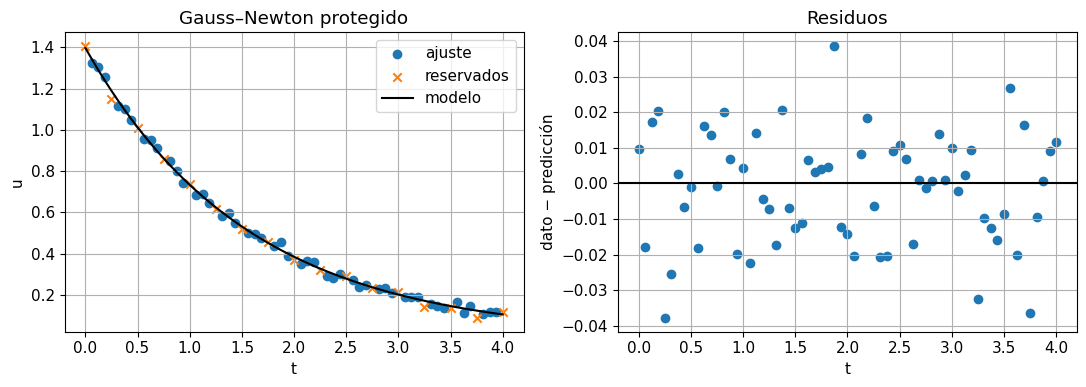

In [4]:
t=np.linspace(0,4,65);truth=np.array([1.4,0.65])
y=truth[0]*np.exp(-truth[1]*t)+rng.normal(0,0.02,len(t))
train=np.arange(len(t))%4!=0
def residual(th):
    a,k=th;return a*np.exp(-k*t[train])-y[train]
def jacobian(th):
    a,k=th;e=np.exp(-k*t[train]);return np.column_stack([e,-a*t[train]*e])
fit=optimize.least_squares(residual,[0.8,1.2],jac=jacobian,bounds=([0,0],[3,3]),method='trf')
assert fit.success
prediction=fit.x[0]*np.exp(-fit.x[1]*t)
print('Parámetros reales:',truth,'Estimados:',fit.x)
print('MSE reservado:',np.mean((prediction[~train]-y[~train])**2))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(t[train],y[train],label='ajuste');ax[0].scatter(t[~train],y[~train],label='reservados',marker='x')
ax[0].plot(t,prediction,'k',label='modelo');ax[0].set(xlabel='t',ylabel='u',title='Gauss–Newton protegido');ax[0].legend()
ax[1].scatter(t,y-prediction);ax[1].axhline(0,c='k');ax[1].set(xlabel='t',ylabel='dato − predicción',title='Residuos')
plt.tight_layout();plt.show()

**Interpretación.** Los residuos deben oscilar sin tendencia sistemática si el modelo y el ruido son razonables. Una curvatura pequeña en alguna dirección de parámetros puede permitir predicciones buenas con parámetros inestables. Verifica siempre tanto el ajuste de estados como la identificabilidad de parámetros.

## 8. Verificación del Jacobiano

Las derivadas analíticas hacen el algoritmo eficiente solo si son correctas. Construimos un Jacobiano por diferencias centrales y comparamos norma relativa. También inspeccionamos los valores singulares: un valor singular pequeño representa una combinación de parámetros con poca influencia observable.

In [5]:
th=np.array([1.1,0.7]);eps=1e-6
Jnum=np.column_stack([(residual(th+eps*np.eye(2)[j])-residual(th-eps*np.eye(2)[j]))/(2*eps) for j in range(2)])
relative_error=np.linalg.norm(jacobian(th)-Jnum)/np.linalg.norm(Jnum)
print('Error relativo del Jacobiano:',relative_error)
print('Valores singulares:',np.linalg.svd(jacobian(fit.x),compute_uv=False))
print('Óptimalidad informada por solver:',fit.optimality)
assert relative_error<1e-7

Error relativo del Jacobiano: 7.977348818315014e-11
Valores singulares: [5.04096 1.82524]
Óptimalidad informada por solver: 2.4442116363028185e-11


## 9. BFGS y L-BFGS: aprender la curvatura

BFGS utiliza cambios $s_k=\theta_{k+1}-\theta_k$ y $y_k=g_{k+1}-g_k$ para actualizar una aproximación al Hessiano o su inversa. Impone una condición secante, por ejemplo $B_{k+1}s_k=y_k$. Si $s_k^Ty_k>0$, una actualización BFGS adecuada preserva definitud positiva.

L-BFGS almacena unas pocas parejas $(s_k,y_k)$ en lugar de una matriz completa. Es útil para objetivos suaves de muchos parámetros con gradientes deterministas. En SciML se utiliza a veces después de Adam, pero ese cambio no remedia datos insuficientes ni un residual físico mal planteado.

## 10. Comparación controlada en Rosenbrock

$J(x,y)=100(y-x^2)^2+(1-x)^2$ tiene mínimo global conocido en $(1,1)$ y un valle curvo. Comparamos BFGS con Newton mediante un método de región de confianza. Ambos disponen del mismo gradiente; solo uno recibe el Hessiano exacto. Registramos el resultado y evaluaciones, no solo iteraciones.

In [6]:
from scipy.optimize import rosen,rosen_der,rosen_hess
for method in ['BFGS','trust-exact']:
    kwargs={'jac':rosen_der}
    if method=='trust-exact':kwargs['hess']=rosen_hess
    r=optimize.minimize(rosen,[-1.2,1.],method=method,**kwargs)
    print(method,'éxito=',r.success,'θ=',r.x,'J=',r.fun,'iter=',r.nit,'eval J=',r.nfev)
    assert np.linalg.norm(r.x-np.ones(2))<1e-3

BFGS éxito= True θ= [1. 1.] J= 2.5353057938593763e-15 iter= 32 eval J= 39
trust-exact éxito= True θ= [1. 1.] J= 3.331252984229145e-19 iter= 25 eval J= 26


## 11. Rango, tolerancia y curvatura casi nula

Un Jacobiano de rango incompleto permite movimientos de parámetros que apenas cambian residuos. Formar $R^TR$ puede ocultar ese diagnóstico y empeorar pérdida de precisión. Para un paso Gauss–Newton didáctico es preferible `np.linalg.lstsq(R, -r, rcond=None)` a calcular una inversa de $R^TR$; una implementación robusta puede además regularizar o imponer cotas.

La curvatura casi nula tiene dos interpretaciones que deben separarse: puede deberse a datos poco informativos o a una representación de parámetros mal escalada. Cambiar unidades y observar si los valores singulares se reorganizan ayuda a detectar el segundo caso. Cambiar tiempos de medición y observar si mejora la información ayuda a detectar el primero.

Al comparar métodos, registra también fallos de factorización, pasos rechazados y norma del gradiente final. Newton puede usar pocas iteraciones pero muchas evaluaciones; un método limitado en memoria puede usar más iteraciones y menos recursos. La elección práctica depende del coste de simular, derivar y resolver sistemas, además de la convergencia local.

## Síntesis y conexión con Scientific Machine Learning

Newton incorpora toda la curvatura local y necesita mecanismos de globalización. Gauss–Newton aprovecha la estructura de mínimos cuadrados; BFGS aproxima la curvatura sin construir el Hessiano exacto. En modelos científicos el coste de cada simulación puede dominar el coste del optimizador.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../10_OPTIMIZACION/10_2_Gradient_methods.ipynb) | [⏩](../10_OPTIMIZACION/10_4_Optimizacion_restringida.ipynb) |